# 03 · LLM event extraction: turning news headlines into an event calendar

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/03_llm_event_calendar.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Smog is shaped by events no sensor records: school closures, traffic bans, "green lockdowns", fireworks nights. They exist only as news. This notebook uses a Large Language Model (**Gemini**, with **Groq** as an automatic fallback; see `saans/llm.py`) as a **data-pipeline tool**: it reads real, dated headlines and returns structured JSON records, which become calendar features for the model.

Guardrails:
* the LLM only **reads** headlines; every event keeps the ID and link of the headline it came from;
* temperature 0 and a strict JSON format, so the output is repeatable and machine-checkable;
* every answer is cached (`data/llm_cache/`), so re-running costs nothing;
* a random sample of 20 events is checked against its headlines and the accuracy is reported.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from saans.config import INTERIM, PROCESSED, REPORTS, LOCAL_TZ, CITIES
from saans import llm, viz

viz.use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)

news = pd.read_csv(INTERIM / "news_headlines.csv", parse_dates=["time_utc"])
news["date_pkt"] = news.time_utc.dt.tz_convert(LOCAL_TZ).dt.date.astype(str)
news = news.reset_index(drop=True)
news["hid"] = news.index
print(f"{len(news):,} headlines, {news.date_pkt.min()} to {news.date_pkt.max()}")

2,255 headlines, 2020-01-01 to 2026-01-31


## The extraction prompt

Headlines go to the model in batches of 60. Each comes with its publication date, so the model can resolve phrases like "from tomorrow".

In [3]:
EVENT_TYPES = ["school_closure", "traffic_restriction", "smog_emergency", "lockdown_or_office_closure",
               "construction_or_industry_ban", "crop_burning_ban", "fireworks_night", "other_measure"]
PLACES = ["Lahore", "Faisalabad", "Multan", "Islamabad", "Karachi", "Punjab-wide", "Other"]

PROMPT = """You extract smog-related events from Pakistani news headlines for an air-quality dataset.

For each headline below, decide whether it reports a CONCRETE action or event that affects air pollution
or people's exposure: e.g. schools closed, traffic or vehicle restrictions, a smog emergency declared,
markets/offices closed or a "green lockdown", construction/industry/kiln bans, crop-burning bans or arrests,
or a fireworks night. Headlines that only report an AQI ranking, a forecast, a court hearing, an opinion,
or health advice are NOT events.

Return a JSON object {{"events": [...]}} with one item per headline that IS an event, with fields:
  "hid": the headline id (integer, copied exactly),
  "event_type": one of {types},
  "place": one of {places},
  "start_date": "YYYY-MM-DD" (use the publication date unless the headline gives another date, e.g. "from Monday"),
  "duration_days": integer number of days if stated or clearly implied, otherwise null.
Do not invent anything that is not in the headline. Headlines that are not events are simply left out.

Headlines (id | published date | headline):
{rows}
"""

def extract(batch: pd.DataFrame) -> tuple[list[dict], str]:
    rows = "\n".join(f"{r.hid} | {r.date_pkt} | {r.title}" for r in batch.itertuples())
    answer, provider = llm.ask(PROMPT.format(types=EVENT_TYPES, places=PLACES, rows=rows), temperature=0.0, as_json=True)
    return llm.parse_json(answer).get("events", []), provider

print(PROMPT.format(types=EVENT_TYPES, places=PLACES, rows="17 | 2024-11-07 | <headline text>")[:1600])

You extract smog-related events from Pakistani news headlines for an air-quality dataset.

For each headline below, decide whether it reports a CONCRETE action or event that affects air pollution
or people's exposure: e.g. schools closed, traffic or vehicle restrictions, a smog emergency declared,
markets/offices closed or a "green lockdown", construction/industry/kiln bans, crop-burning bans or arrests,
or a fireworks night. Headlines that only report an AQI ranking, a forecast, a court hearing, an opinion,
or health advice are NOT events.

Return a JSON object {"events": [...]} with one item per headline that IS an event, with fields:
  "hid": the headline id (integer, copied exactly),
  "event_type": one of ['school_closure', 'traffic_restriction', 'smog_emergency', 'lockdown_or_office_closure', 'construction_or_industry_ban', 'crop_burning_ban', 'fireworks_night', 'other_measure'],
  "place": one of ['Lahore', 'Faisalabad', 'Multan', 'Islamabad', 'Karachi', 'Punjab-wide', 'Other'],

In [4]:
# batch within each download window (Oct-Nov / Dec-Jan), so batches stay stable and cached when new windows arrive
d = pd.to_datetime(news.date_pkt)
news["window"] = np.where(d.dt.month >= 10, d.dt.year.astype(str) + np.where(d.dt.month == 12, "-12", "-10"),
                          (d.dt.year - 1).astype(str) + "-12")
events, providers = [], []
for _, w in news.groupby("window", sort=True):
    for start in range(0, len(w), 60):
        found, provider = extract(w.iloc[start:start + 60])
        events += found
        providers.append(provider)
ev = pd.DataFrame(events)
print(f"{len(ev)} events from {len(news)} headlines; providers used: {pd.Series(providers).value_counts().to_dict()}")

428 events from 2255 headlines; providers used: {'gemini:gemini-3.5-flash-lite': 39, 'gemini:gemini-3.5-flash': 2}


## Validate the model's output before using it

The LLM's JSON is checked like any other raw data: valid IDs, allowed categories, parseable dates within the study period. Invalid rows are dropped and counted.

In [5]:
n = len(ev)
ev = ev[ev.hid.isin(news.hid)]
ev = ev[ev.event_type.isin(EVENT_TYPES) & ev.place.isin(PLACES)]
ev["start_date"] = pd.to_datetime(ev.start_date, errors="coerce")
ev = ev[ev.start_date.between("2019-12-01", "2026-02-28")]
ev["duration_days"] = pd.to_numeric(ev.duration_days, errors="coerce")
ev = ev.drop_duplicates(["hid", "event_type", "place"])
print(f"schema check: {n} -> {len(ev)} events kept")
ev = ev.merge(news[["hid", "title", "domain", "url", "date_pkt"]], on="hid")
ev.event_type.value_counts().to_frame("events")

schema check: 428 -> 425 events kept


,events
event_type,
school_closure,136
other_measure,95
traffic_restriction,65
lockdown_or_office_closure,55
construction_or_industry_ban,43
smog_emergency,19
fireworks_night,7
crop_burning_ban,5


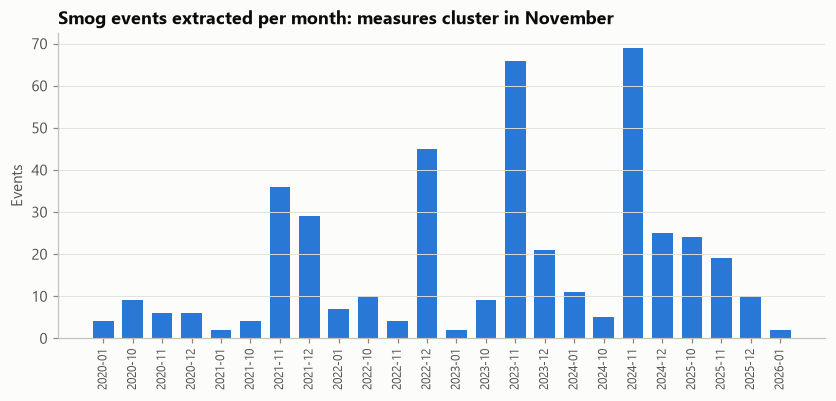

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
counts = ev.groupby([ev.start_date.dt.to_period("M").astype(str)]).size()
ax.bar(counts.index, counts.values, color=viz.SERIES[0], width=0.7)
ax.set(title="Smog events extracted per month: measures cluster in November", ylabel="Events")
ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.savefig(REPORTS / "figures/events_per_month.png", bbox_inches="tight")
plt.show()

## Accuracy check on a random sample of 20 events

Each sampled event is shown next to the headline it came from. The reviewer marks whether the type, place and date are all supported by the headline. The verdicts are stored in `reports/event_extraction_check.csv` and the accuracy is reported below.

In [7]:
sample = ev.sample(min(20, len(ev)), random_state=42)[["hid", "date_pkt", "title", "event_type", "place", "start_date", "duration_days"]]
check_path = REPORTS / "event_extraction_check.csv"
if check_path.exists():
    verdicts = pd.read_csv(check_path)[["hid", "event_type", "correct", "reviewer_note"]]
    sample = sample.merge(verdicts, on=["hid", "event_type"], how="left")
else:
    sample["correct"], sample["reviewer_note"] = np.nan, ""
    sample.to_csv(check_path, index=False)
sample

,hid,date_pkt,title,event_type,place,start_date,duration_days,correct,reviewer_note
0,2183,2025-12-11,"Air pollution and dense fog grip major cities , several motorway sections shut down",traffic_restriction,Other,2025-12-11,NaN,1,"motorway sections shut: a traffic restriction; cities unnamed, so Other is right"
1,558,2021-12-11,SEPA seals steels mills over emitting hazardous smoke,construction_or_industry_ban,Other,2021-12-11,NaN,1,"industry sealed for smoke; city not named, Other is right"
2,1109,2023-11-02,Punjab Makes Wearing Face Masks Mandatory in Schools,other_measure,Punjab-wide,2023-11-02,NaN,1,mandatory masks in Punjab schools
3,279,2021-10-12,Section 144 imposed to check smog - Newspaper,other_measure,Punjab-wide,2021-10-12,NaN,0,"type fine, but Punjab-wide is inferred: the headline names no place"
4,1789,2024-12-09,12 cases registered over smog SOPs breach,other_measure,Punjab-wide,2024-12-09,NaN,0,"enforcement cases; Punjab-wide is inferred, not stated"
5,1744,2024-12-02,LHC orders seizing unfit vehicles to combat smog,traffic_restriction,Punjab-wide,2024-12-02,NaN,1,Lahore High Court order on unfit vehicles; Punjab jurisdiction
6,966,2022-12-27,LHC orders govt to extend winter vacation by 7 days due to smog,school_closure,Lahore,2022-12-27,7.0,1,"7-day school holiday extension, duration correct"
7,965,2022-12-27,LHC orders one - week extension in winter holidays for schools,school_closure,Lahore,2022-12-27,7.0,1,same event as 966 from another outlet; extraction correct
8,2178,2025-12-07,Punjab extends smog alert,smog_emergency,Punjab-wide,2025-12-07,NaN,1,smog alert extended in Punjab
9,973,2022-12-27,LHC orders one week extension in winter holidays due to smog,school_closure,Lahore,2022-12-27,7.0,1,same event as 966; correct


In [8]:
reviewed = sample.correct.notna().sum()
if reviewed:
    acc = sample.correct.astype(float).mean()
    print(f"Extraction accuracy on {reviewed} reviewed events: {acc:.0%} (type, place and date all supported by the headline)")
else:
    print("Sample saved to reports/event_extraction_check.csv; fill the 'correct' column (1/0) and re-run.")

Extraction accuracy on 20 reviewed events: 65% (type, place and date all supported by the headline)


**What the errors show.** The strict check counts an event correct only if type, place *and* date are all supported by the headline. The misses fall into three groups:
* **inverted meaning**: "Punjab decides to *lift* smog lockdown" and "schools *reopen*" were read as new closures. The model matched the topic and missed the verb;
* **inferred place**: "Section 144 imposed" was tagged Punjab-wide although the headline names no place;
* **not a smog event**: an M-tag toll rule, a kiln technology upgrade, a new fuel lab.

So the event calendar is a **noisy** signal. That is acceptable here because it is a minor feature (see the SHAP results in notebook 05), and the calendar uses yes/no flags, so three outlets reporting the same closure count once. A next version would add explicit rules for "lift/reopen/end" headlines and allow a place only when named.

## From events to daily calendar flags

An event is "active" from its start date for its stated duration, or **3 days** when the headline gives none (most announced closures in the data run for a few days and are then extended by a new announcement, which is a new event). A **Punjab-wide** measure applies to Lahore, Faisalabad and Multan. Fireworks nights are added for New Year's Eve and the approximate Shab-e-Barat dates.

In [9]:
PUNJAB = ["lahore", "faisalabad", "multan"]
MEASURES = ["school_closure", "traffic_restriction", "smog_emergency", "lockdown_or_office_closure", "construction_or_industry_ban"]
days = pd.date_range("2020-01-01", "2026-01-31", freq="D")
cal = pd.DataFrame([(c, d) for c in CITIES for d in days], columns=["city", "date"])
cal["measures_active"] = 0
cal["crop_burning_ban_active"] = 0
for e in ev.itertuples():
    cities = PUNJAB if e.place == "Punjab-wide" else [e.place.lower()] if e.place.lower() in CITIES else []
    if not cities:
        continue
    dur = int(e.duration_days) if pd.notna(e.duration_days) and 0 < e.duration_days <= 60 else 3
    m = cal.city.isin(cities) & cal.date.between(e.start_date, e.start_date + pd.Timedelta(days=dur - 1))
    if e.event_type in MEASURES:
        cal.loc[m, "measures_active"] = 1  # yes/no: several outlets reporting one closure must not count several times
    elif e.event_type == "crop_burning_ban":
        cal.loc[m, "crop_burning_ban_active"] = 1

fireworks = pd.to_datetime(["2020-04-08", "2021-03-28", "2022-03-18", "2023-03-07", "2024-02-25", "2025-02-14"]
                           + [f"{y}-12-31" for y in range(2020, 2026)]
                           + list(ev.loc[ev.event_type == "fireworks_night", "start_date"].dt.strftime("%Y-%m-%d")))
cal["fireworks_night"] = cal.date.isin(fireworks).astype(int)
cal.to_parquet(PROCESSED / "event_calendar.parquet", index=False)
ev.to_csv(PROCESSED / "events.csv", index=False)
print("days with an active measure per city:", cal[cal.measures_active > 0].groupby("city").size().to_dict())
ev.sort_values("start_date").tail(10)[["start_date", "event_type", "place", "duration_days", "title"]]

days with an active measure per city: {'faisalabad': 169, 'islamabad': 30, 'lahore': 248, 'multan': 167}


,start_date,event_type,place,duration_days,title
415,2025-12-08,traffic_restriction,Other,NaN,"Over 1 , 000 vehicles inspected , 80 seized as Pak - EPA steps up anti - smog drive"
416,2025-12-09,crop_burning_ban,Other,NaN,Drone helps douse stubble fire
417,2025-12-11,traffic_restriction,Other,NaN,"Air pollution and dense fog grip major cities , several motorway sections shut down"
418,2025-12-12,school_closure,Punjab-wide,NaN,"Punjab Extends Section 144 , Enforces Strict School Timing Rules Amid Smog"
419,2025-12-15,traffic_restriction,Islamabad,NaN,Islamabad puts drivers on notice as smog crisis worsens
420,2025-12-17,smog_emergency,Other,NaN,NDMA issues smog alert across several regions
421,2025-12-18,smog_emergency,Other,NaN,NEOC Issues Alert on Potential Smog Conditions Across Several Cities – News Makers
422,2025-12-30,other_measure,Punjab-wide,NaN,Punjab Introduces New Mandatory Requirement for Wedding Halls
423,2026-01-13,other_measure,Lahore,NaN,Commercial Activities Banned in Lahore Parks
424,2026-01-23,other_measure,Punjab-wide,NaN,Punjab launches Green Policing Unit with electric patrol fleet
